# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name: Fateh Noor**
- **Student ID: 023-24-0110**
- **Section: D**
- **GitHub: https://github.com/noormangi17/ML-Tasks/tree/main/Lab8**
- **Kaggle:**
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** <paste the Kaggle URL you used>

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
import pandas as pd
import numpy as np
df=pd.read_csv("dataset.csv")
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors='coerce')
df["TotalCharges"]=df["TotalCharges"].fillna(df["TotalCharges"].mean())
df.drop(columns=["customerID"],inplace=True)


In [2]:
y=df["Churn"].map({"Yes":1,"No":0})
x=df.drop(columns=["Churn"])
x=pd.get_dummies(x,drop_first=True)
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [3]:
# YOUR CODE HERE — unscaled linear SVM
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(x_train, y_train)
unscaled_pred=svm_raw.predict(x_test)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
raw_acc=accuracy_score(y_test, unscaled_pred)
raw_prec=precision_score(y_test, unscaled_pred)
raw_rec=recall_score(y_test, unscaled_pred)
raw_f1=f1_score(y_test, unscaled_pred)
print(f"Unscaled SVM\nAccuracy: {raw_acc:.4f}, Precision: {raw_prec:.4f}, Recall: {raw_rec:.4f}, F1 Score: {raw_f1:.4f}")



Unscaled SVM
Accuracy: 0.7935, Precision: 0.6708, Recall: 0.4358, F1 Score: 0.5284


In [4]:
# YOUR CODE HERE — scaled linear SVM
# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_test_s  = scaler.transform(x_test)
svm_scaled = SVC(kernel='linear', random_state=42)
svm_scaled.fit(x_train_s, y_train)
scaled_pred=svm_scaled.predict(x_test_s)
scaled_acc=accuracy_score(y_test, scaled_pred)
scaled_prec=precision_score(y_test, scaled_pred)
scaled_rec=recall_score(y_test, scaled_pred)
scaled_f1=f1_score(y_test, scaled_pred)
print(f"Scaled SVM\nAccuracy: {scaled_acc:.4f}, Precision: {scaled_prec:.4f}, Recall: {scaled_rec:.4f}, F1 Score: {scaled_f1:.4f}")

Scaled SVM
Accuracy: 0.7892, Precision: 0.6207, Recall: 0.5294, F1 Score: 0.5714


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?<br>
The unscaled SVM achieved an accuracy of 79.35%, precision of 67.08%, recall of 43.58%, and F1-score of 52.84%. It took approximately 3 minutes to train.<br>
The scaled SVM achieved an accuracy of 78.92%, precision of 62.07%, recall of 52.94%, and F1-score of 57.14%. It took only 1.4 seconds to train.
The scaled model had slightly lower accuracy but better recall and F1-score. It also trained significantly faster. No warnings were displayed in either execution.<br>

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?<br>
An unscaled SVM is affected by differences in feature magnitudes. Features with larger numerical values can dominate the distance and margin calculations, causing the decision boundary to become biased toward those features. This can make optimization slower and reduce model performance.<br>
Scaling puts features on a similar range, allowing SVM to calculate a more balanced decision boundary and optimize faster.<br>

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?<br>
I will use the scaled SVM for all subsequent SVM experiments because feature scaling improves training efficiency and provides better recall and F1-score in my results. It also ensures that features contribute more fairly to the decision boundary, making the model more reliable.

---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [19]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics

# Linear SVM
svm_linear = SVC(kernel='linear', random_state=42)
svm_linear.fit(x_train_s, y_train)
linear_pred = svm_linear.predict(x_test_s)
linear_acc = accuracy_score(y_test, linear_pred)
linear_prec = precision_score(y_test, linear_pred)
linear_rec = recall_score(y_test, linear_pred)
linear_f1 = f1_score(y_test, linear_pred)
linear_sv=svm_linear.support_vectors_.shape[0]
print(f"Linear SVM\nAccuracy: {linear_acc:.4f}, Precision: {linear_prec:.4f}, Recall: {linear_rec:.4f}, F1 Score: {linear_f1:.4f}, Support Vectors: {linear_sv}")

# RBF SVM
svm_rbf = SVC(kernel='rbf', random_state=42)
svm_rbf.fit(x_train_s, y_train)
rbf_pred = svm_rbf.predict(x_test_s)
rbf_acc = accuracy_score(y_test, rbf_pred)
rbf_prec = precision_score(y_test, rbf_pred)
rbf_rec = recall_score(y_test, rbf_pred)
rbf_f1 = f1_score(y_test, rbf_pred)
rbf_sv=svm_rbf.support_vectors_.shape[0]
print(f"RBF SVM\nAccuracy: {rbf_acc:.4f}, Precision: {rbf_prec:.4f}, Recall: {rbf_rec:.4f}, F1 Score: {rbf_f1:.4f}, Support Vectors: {rbf_sv}")

# Polynomial SVM
svm_poly = SVC(kernel='poly', random_state=42)
svm_poly.fit(x_train_s, y_train)
poly_pred = svm_poly.predict(x_test_s)
poly_acc = accuracy_score(y_test, poly_pred)
poly_prec = precision_score(y_test, poly_pred)
poly_rec = recall_score(y_test, poly_pred)
poly_f1 = f1_score(y_test, poly_pred)
poly_sv=svm_poly.support_vectors_.shape[0]
print(f"Polynomial SVM\nAccuracy: {poly_acc:.4f}, Precision: {poly_prec:.4f}, Recall: {poly_rec:.4f}, F1 Score: {poly_f1:.4f}, Support Vectors: {poly_sv}")


Linear SVM
Accuracy: 0.7892, Precision: 0.6207, Recall: 0.5294, F1 Score: 0.5714, Support Vectors: 2569
RBF SVM
Accuracy: 0.7928, Precision: 0.6444, Recall: 0.4893, F1 Score: 0.5562, Support Vectors: 2660
Polynomial SVM
Accuracy: 0.7892, Precision: 0.6421, Recall: 0.4652, F1 Score: 0.5395, Support Vectors: 2738


In [21]:
# YOUR CODE HERE — comparison table
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM", "Polynomial SVM"],
    "Accuracy": [0.7892, 0.7928, 0.7892],
    "Precision": [0.6207, 0.6444, 0.6421],
    "Recall": [0.5294, 0.4893, 0.4652],
    "F1 Score": [0.5714, 0.5562, 0.5395],
    "Support Vectors": [2569, 2660, 2738]
})
comparison

,Model,Accuracy,Precision,Recall,F1 Score,Support Vectors
0,Linear SVM,0.7892,0.6207,0.5294,0.5714,2569
1,RBF SVM,0.7928,0.6444,0.4893,0.5562,2660
2,Polynomial SVM,0.7892,0.6421,0.4652,0.5395,2738


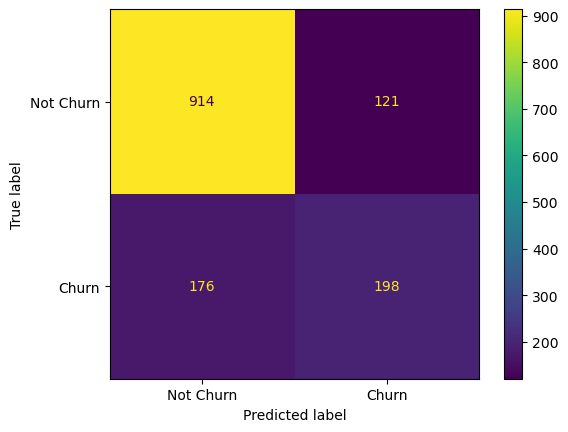

In [29]:
# YOUR CODE HERE — confusion matrix for the best kernel
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm=confusion_matrix(y_test, linear_pred)
ConfusionMatrixDisplay(cm, display_labels=["Not Churn", "Churn"]).plot()

**Questions to answer:**<br>
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?<br>
The Linear SVM produced the best F1-score of 0.5714 (57.14%). RBF achieved 0.5562, while Polynomial achieved 0.5395. This is slightly surprising because RBF kernels can capture complex non-linear patterns, but in this dataset, the simpler linear decision boundary performed better.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?<br>
The Polynomial SVM used the most support vectors (2738), followed by RBF (2660) and Linear (2569). A high support-vector count suggests that more training samples are involved in defining the decision boundary. It may indicate a more complex boundary or greater overlap between classes.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.<br>
I would carry forward the Linear SVM for hyperparameter tuning because it achieved the highest F1-score (0.5714) and recall (0.5294), with only 2569 support vectors. Although RBF had slightly higher accuracy (0.7928 vs. 0.7892) and precision (0.6444 vs. 0.6207), Linear SVM provides a better balance between precision and recall. Therefore, it is the most suitable candidate for further tuning.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [32]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
x_train_pca = pca.fit_transform(x_train_s)
# Explained variance of each component
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
# Total explained variance
total_variance = sum(pca.explained_variance_ratio_)
print(f"Total Explained Variance: {total_variance:.4f}")
print(f"Percentage: {total_variance * 100:.2f}%")

Explained Variance Ratio: [0.33244768 0.11982102]
Total Explained Variance: 0.4523
Percentage: 45.23%


In [33]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
from sklearn.svm import SVC
# Small C
svm_small = SVC(kernel='rbf', C=0.01, random_state=42)
svm_small.fit(x_train_pca, y_train)
# Medium C
svm_medium = SVC(kernel='rbf', C=1, random_state=42)
svm_medium.fit(x_train_pca, y_train)
# Large C
svm_large = SVC(kernel='rbf', C=100, random_state=42)
svm_large.fit(x_train_pca, y_train)

,C,100
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


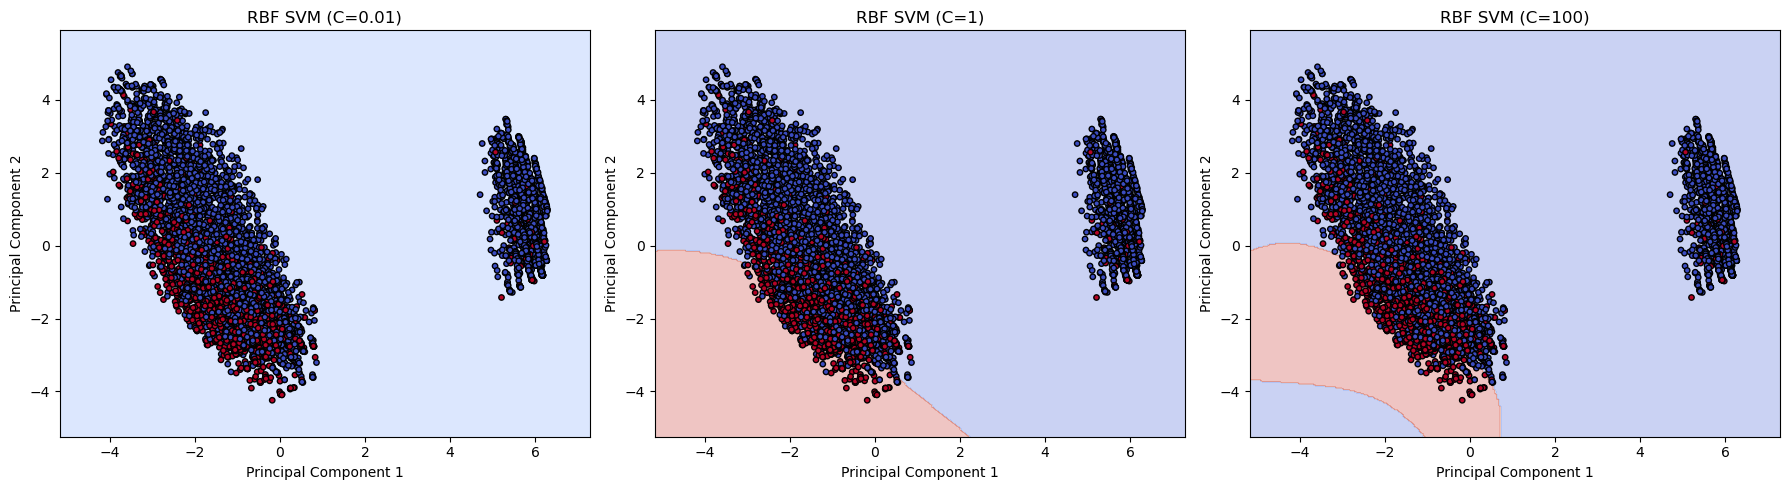

In [34]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
import numpy as np
import matplotlib.pyplot as plt

# Create mesh grid
x_min, x_max = x_train_pca[:, 0].min() - 1, x_train_pca[:, 0].max() + 1
y_min, y_max = x_train_pca[:, 1].min() - 1, x_train_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Three trained models
models = [
    (svm_small, 0.01),
    (svm_medium, 1),
    (svm_large, 100)
]

# Plot decision boundaries
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model, c_value) in zip(axes, models):

    # Predict on every point of mesh grid
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid_points)

    Z = Z.reshape(xx.shape)

    # Plot decision regions
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

    # Plot training data
    ax.scatter(
        x_train_pca[:, 0],
        x_train_pca[:, 1],
        c=y_train,
        cmap='coolwarm',
        edgecolors='black',
        s=15
    )

    ax.set_title(f'RBF SVM (C={c_value})')
    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')

plt.tight_layout()
plt.show()


**Questions to answer:**<br>
(a) How does the shape/smoothness of the decision boundary change as C increases?

*As C increases, the decision boundary becomes more defined and changes its shape to classify training points more accurately. At C=0.01, the boundary is almost uniform, while at C=1 and C=100, curved decision regions become visible. The boundary becomes more flexible as C increases.*

(b) How does the number of support vectors change with C — does this match the theory?

*The number of support vectors depends on the value of C and the distribution of data points. A higher C penalizes classification errors more strongly, but it does not necessarily decrease the number of support vectors. We need to compare the actual support-vector counts to determine the trend.*

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*C=0.01 appears to be underfitting because its decision boundary is almost uniform and fails to separate the two classes effectively.
C=100 appears more flexible and potentially more prone to overfitting because it creates a more defined curved boundary around the data. C=1 provides a reasonable intermediate result.*

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*The plot uses only two principal components (PC1 and PC2), whereas the original dataset contains multiple features. PCA reduces dimensionality and may discard important information. Therefore, the displayed decision boundaries may differ from the actual boundaries learned using all original features. The visualization may give an incomplete picture of the model's true classification performance.*


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [36]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# Define parameter grid
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [0.01, 0.1, 1]
}

# Create RBF SVM
svm = SVC(kernel='rbf', random_state=42)

# Apply GridSearchCV
gs = GridSearchCV(
    svm,
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

# Train on scaled training data
gs.fit(x_train_s, y_train)

print("Best Parameters:", gs.best_params_)
print("Best CV F1 Score:", gs.best_score_)


Best Parameters: {'C': 10, 'gamma': 0.01}
Best CV F1 Score: 0.5852822456612709


param_gamma      0.01      0.10      1.00
param_C                                  
0.1          0.541689  0.463951  0.000000
1.0          0.565038  0.573405  0.326124
10.0         0.585282  0.526574  0.362099


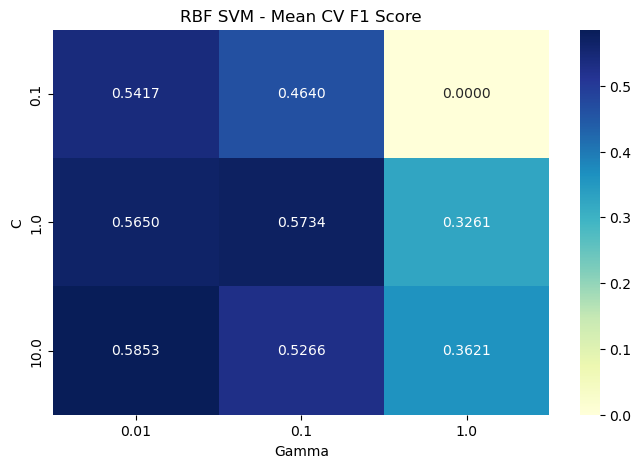

In [37]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract results
results = pd.DataFrame(gs.cv_results_)

# Create C x gamma grid
heatmap_data = results.pivot(
    index='param_C',
    columns='param_gamma',
    values='mean_test_score'
)

print(heatmap_data)

# Plot heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.4f',
    cmap='YlGnBu'
)

plt.title('RBF SVM - Mean CV F1 Score')
plt.xlabel('Gamma')
plt.ylabel('C')

plt.show()

In [39]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Get best model
best_svm = gs.best_estimator_

# Predict on scaled test data
y_pred = best_svm.predict(x_test_s)

# Evaluate performance
print("Best RBF SVM Test Performance")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))


Best RBF SVM Test Performance
Accuracy: 0.7885024840312278
Precision: 0.62751677852349
Recall: 0.5
F1 Score: 0.5565476190476191


**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*The best hyperparameters found by GridSearchCV were C = 10 and gamma = 0.01, with a cross-validated F1-score of 0.5853 (58.53%).*

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Several combinations performed similarly, especially C=10 with gamma=0.01 (0.5853) and C=1 with gamma=0.1 (0.5734). Lower gamma values generally performed better. This suggests that the model benefits from smoother decision boundaries and that multiple hyperparameter combinations can produce reasonable results.*

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*The cross-validated F1-score was 0.5853, while the final test F1-score was 0.5565, a difference of approximately 0.0287 (2.87 percentage points). This is a relatively small gap, suggesting reasonable generalization. A large gap could indicate overfitting or that the validation data is not representative of the test data.*

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

|Metric|Untuned RBF|Tuned RBF|
|--:|--:|--:|
Accuracy|0.7928|0.7885
Precision|	0.6444|	0.6275
Recall	|0.4893	|0.5000
F1-score|	0.5562	|0.5565


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [42]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
from sklearn.svm import SVC
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, accuracy_score
)

# Model 1: Without class balancing
svm_none = SVC(
    kernel='rbf',
    C=10,
    gamma=0.01,
    class_weight=None,
    random_state=42
)

svm_none.fit(x_train_s, y_train)
pred_none = svm_none.predict(x_test_s)


# Model 2: With class balancing
svm_balanced = SVC(
    kernel='rbf',
    C=10,
    gamma=0.01,
    class_weight='balanced',
    random_state=42
)

svm_balanced.fit(x_train_s, y_train)
pred_balanced = svm_balanced.predict(x_test_s)


# Evaluation function
def evaluate_model(name, y_true, y_pred):

    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall:", recall_score(y_true, y_pred))
    print("F1 Score:", f1_score(y_true, y_pred))

    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))


# Compare both models
evaluate_model("RBF SVM - Without Balancing", y_test, pred_none)

evaluate_model("RBF SVM - With Balanced Weights", y_test, pred_balanced)



RBF SVM - Without Balancing
Accuracy: 0.7885024840312278
Precision: 0.62751677852349
Recall: 0.5
F1 Score: 0.5565476190476191
Confusion Matrix:
[[924 111]
 [187 187]]

RBF SVM - With Balanced Weights
Accuracy: 0.7402413058907026
Precision: 0.5069686411149826
Recall: 0.7780748663101604
F1 Score: 0.6139240506329114
Confusion Matrix:
[[752 283]
 [ 83 291]]


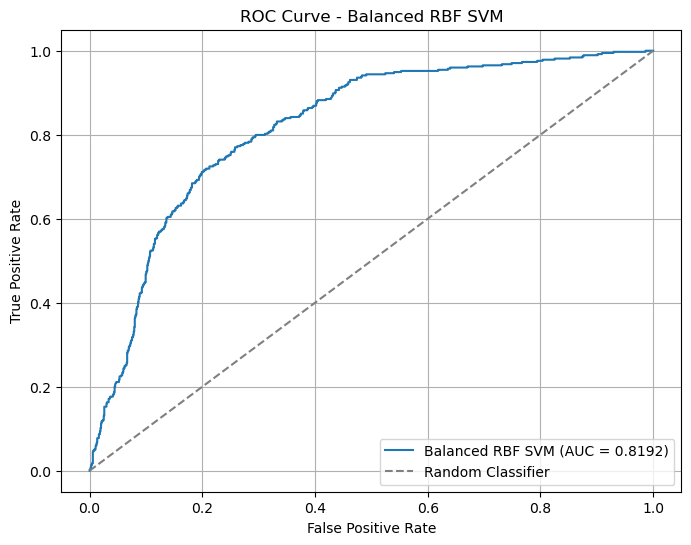

In [44]:
# YOUR CODE HERE — ROC or Precision-Recall curve
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Get prediction probabilities/scores
y_scores = svm_balanced.decision_function(x_test_s)

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

# Calculate AUC
auc = roc_auc_score(y_test, y_scores)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f'Balanced RBF SVM (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray',
         label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Balanced RBF SVM')

plt.legend()
plt.grid()
plt.show()

**Questions to answer:**<br>
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*When switching to class_weight='balanced':
- Precision decreased from 0.6275 (62.75%) to 0.5070 (50.70%).
- Recall increased from 0.5000 (50%) to 0.7781 (77.81%).
This means the balanced model identifies more actual churners but also produces more false positives.*

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*It is generally more costly to miss an actual churner (false negative) because the business may lose a customer without attempting to retain them.

I would deploy the balanced RBF SVM because its recall increased from 50% to 77.81%, and its F1-score improved from 0.5565 to 0.6139. Although it produces more false positives, identifying more potential churners can help the business take preventive retention actions.

The confusion matrices also support this:
- Without balancing: 187 false negatives.
- With balancing: 83 false negatives.
The balanced model misses 104 fewer actual churners.*

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*To obtain probability-like churn scores from SVM, we need to enable the probability parameter in the SVC model. This allows SVM to estimate the probability of a customer belonging to the positive class (churn). These probability estimates can then be used for further analysis and decision-making.*


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [45]:
# YOUR CODE HERE — cross-model comparison table
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

# Define five models
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),

    "KNN": KNeighborsClassifier(n_neighbors=5),

    "SVM": SVC(
        kernel='rbf',
        C=10,
        gamma=0.01,
        class_weight='balanced',
        random_state=42
    )
}

results = []

# Train and evaluate models
for name, model in models.items():

    if name in ["Decision Tree", "Random Forest"]:
        model.fit(x_train, y_train)
        predictions = model.predict(x_test)

    elif name == "SVM":
        model.fit(x_train_s, y_train)
        predictions = model.predict(x_test_s)

    else:
        model.fit(x_train_s, y_train)
        predictions = model.predict(x_test_s)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

# Create comparison DataFrame
final_comparison = pd.DataFrame(results)

print(final_comparison.round(4))


                 Model  Accuracy  Precision  Recall  F1 Score
0        Decision Tree    0.7417     0.5139  0.4947    0.5041
1        Random Forest    0.7878     0.6280  0.4920    0.5517
2  Logistic Regression    0.8070     0.6584  0.5668    0.6092
3                  KNN    0.7473     0.5253  0.5000    0.5123
4                  SVM    0.7402     0.5070  0.7781    0.6139


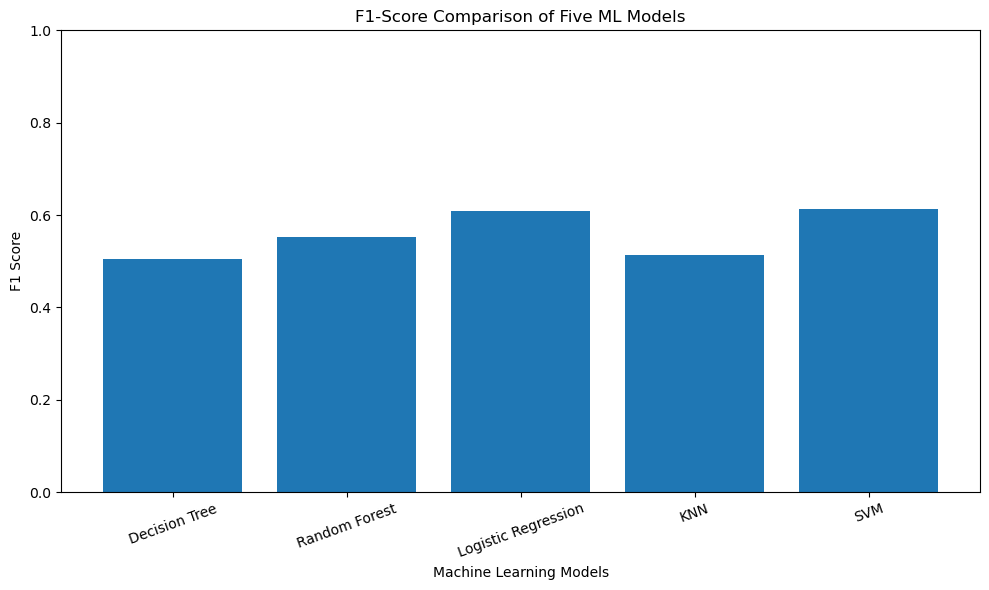

In [46]:
# YOUR CODE HERE — bar chart of F1-score across models
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    final_comparison["Model"],
    final_comparison["F1 Score"]
)

plt.title("F1-Score Comparison of Five ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("F1 Score")

plt.xticks(rotation=20)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

**Questions to answer:**<br>
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*SVM wins on both F1-score and Recall.
- Highest F1-score: SVM = 0.6139 (61.39%)
- Highest Recall: SVM = 0.7781 (77.81%)
Yes, both are achieved by SVM. It performs better at identifying actual churners while maintaining the highest overall balance between precision and recall.*

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Yes, the extra computational cost is worth it in this case. SVM achieved the highest F1-score (0.6139) and Recall (0.7781) among all five models. Its higher recall means fewer actual churners are missed, which is important for customer retention. Therefore, its improved performance justifies the additional training cost.*

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*I would recommend deploying the Balanced RBF SVM model.
It achieved the highest F1-score of 0.6139 and the highest Recall of 0.7781 among all five models. Although its precision (0.5070) and accuracy (0.7402) are lower than Logistic Regression, it identifies more potential churners. This allows the business to take early retention actions and reduce customer loss. Therefore, SVM is the most suitable choice when identifying potential churners is the main business priority.*


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [49]:
# YOUR CODE HERE — generate and save svm_predictions.csv
import pandas as pd

# Generate predictions
final_predictions = svm_balanced.predict(x_test_s)

# Generate continuous churn scores
churn_scores = svm_balanced.decision_function(x_test_s)

# Create prediction DataFrame
prediction_df = pd.DataFrame({
    "True_Label": y_test.values,
    "Predicted_Label": final_predictions,
    "Churn_Score": churn_scores
})

# Save CSV file
prediction_df.to_csv("svm_predictions.csv", index=False)

print("CSV file saved successfully!")
print(prediction_df.head())


CSV file saved successfully!
   True_Label  Predicted_Label  Churn_Score
0           0                0    -1.369712
1           0                1     1.403268
2           0                0    -1.511111
3           0                1     0.573009
4           0                0    -1.577039


**Executive Summary**

*The Balanced RBF SVM was selected as the final model for customer churn prediction. It achieved an accuracy of 74.02%, precision of 50.70%, recall of 77.81%, and an F1-score of 61.39%. Compared with the other four algorithms, it achieved the highest recall and F1-score. The main trade-off in Part 5 was that class balancing increased recall from 50% to 77.81%, but decreased precision from 62.75% to 50.70%. This means the model identifies more actual churners but also incorrectly flags more loyal customers. The model is useful for businesses that prioritize customer retention and want to identify potential churners early. One limitation is that the model produces false positives, which may increase customer retention campaign costs.*

**Final Reflection**
(a) What was the single most surprising result in this lab?

*The most surprising result was that applying class_weight='balanced' significantly improved the SVM model's recall from 50% to 77.81% and F1-score from 55.65% to 61.39%. However, its accuracy and precision decreased. This showed how handling class imbalance can significantly change model performance.*

(b) If you had one more hour, what would you try next?

*If I had one more hour, I would experiment with different classification thresholds to improve the balance between precision and recall. I would also try additional hyperparameter combinations using GridSearchCV and compare their performance. This could help reduce false positives while maintaining high recall and improving the model's overall performance.*
